# Assignment 3: Fashion-MNIST Classification

**IE500618 Machine Learning, individual assignment**

Candidate: **Kristian Løkkeberg**

Four small neural networks that classify images of clothing. Part A trains and compares them, Part B answers Q1-Q4 and Part C looks at the confusion matrix.

## 0. Setup
Settings used by every model:

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 67 # same seed for the split and the starting weights
EPOCHS = 10 # from the assignment
BATCH_SIZE = 64

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

I0000 00:00:1793893585.274005   36114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793893585.274343   36114 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793893585.309660   36114 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793893586.237650   36114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## 1. Dataset and preparation

*Use the Fashion-MNIST dataset (`tf.keras.datasets.fashion_mnist.load_data()`), containing 28 × 28 grayscale images in 10 clothing categories. Normalize the pixel values to 0–1 and flatten each image into 784 input features (or use a Keras Flatten layer).*

### 1.1 Load the data
X is the images and y is the labels (0-9):

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print(X_train_full.shape, y_train_full.shape) # (images, rows, columns)
print(X_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


### 1.2 Look at the data
The first 25 images and their labels:

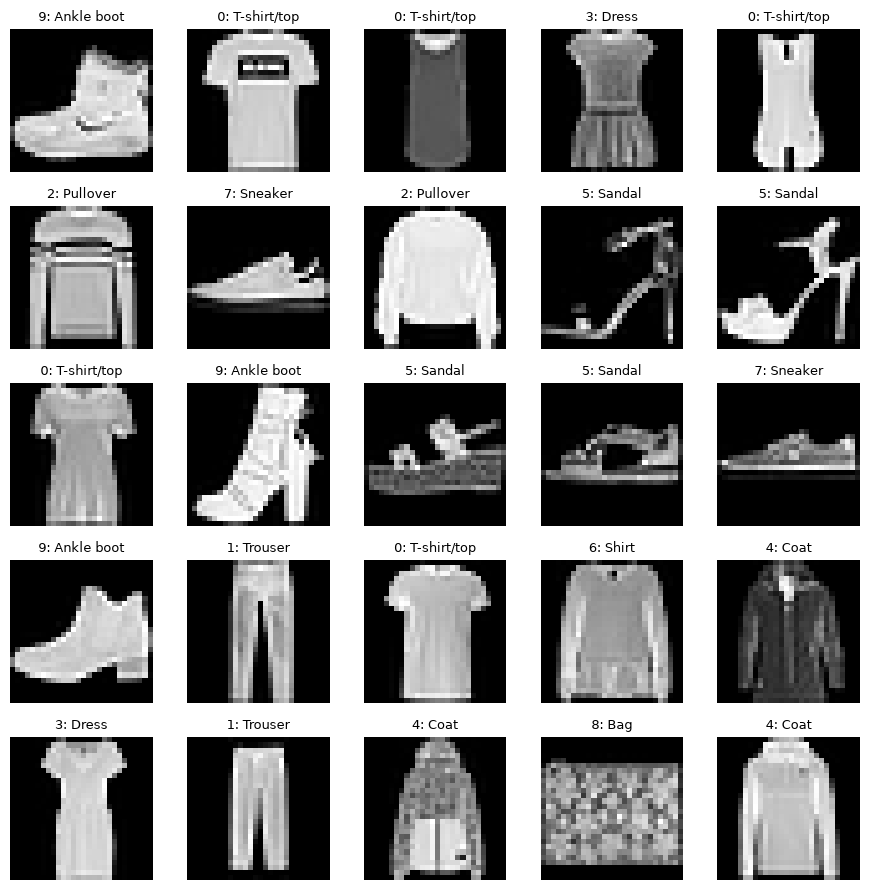

In [3]:
plt.figure(figsize=(9, 9))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(f"{y_train_full[i]}: {CLASS_NAMES[y_train_full[i]]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### 1.3 Normalize
The pixels go from 0 to 255, so we divide by 255 to get them between 0 and 1:

In [4]:
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

### 1.4 Validation set
80/20 split, so 48 000 to train on and 12 000 to validate on. The test set isn't used before Task 3, and the flattening is done by a `Flatten` layer in the model:

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=SEED
)

print(len(X_train), len(X_val), len(X_test))

48000 12000 10000


---
## Part A: Build and compare neural networks

### Helper function
All four models are built the same way, so one function builds, compiles, trains and saves the accuracy. The seed is reset every time so all models start with the same weights:

In [6]:
results = {} # one entry per model

def build_and_train(name, hidden_neurons, activation, optimizer):
    tf.keras.utils.set_random_seed(SEED) # same starting weights every time

    # Build
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_neurons, activation=activation),
        tf.keras.layers.Dense(10, activation="softmax")
    ], name=name.replace(" ", "_"))

    # Compile
    model.compile(
        optimizer=optimizer, # default settings
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # train
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        verbose=2 # one line per epoch
    )

    # save the last epoch
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]

    results[name] = {
        "model": model, "history": history,
        "neurons": hidden_neurons, "activation": activation, "optimizer": optimizer,
        "train_acc": train_acc, "val_acc": val_acc,
    }
    return model

---
### Task 1: Baseline
*Build a baseline model with one hidden layer of 32 neurons using ReLU activation and the Adam optimizer. Train it and record its training and validation accuracy.*

The baseline that everything else is compared to:

In [7]:
baseline = build_and_train("Baseline", hidden_neurons=32, activation="relu", optimizer="adam")
baseline.summary()

Epoch 1/10


E0000 00:00:1793893588.259310   36114 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793893588.259594   36184 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793893588.274761   36114 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


750/750 - 1s - 2ms/step - accuracy: 0.7969 - loss: 0.6091 - val_accuracy: 0.8438 - val_loss: 0.4574
Epoch 2/10
750/750 - 1s - 1ms/step - accuracy: 0.8454 - loss: 0.4398 - val_accuracy: 0.8574 - val_loss: 0.4129
Epoch 3/10
750/750 - 1s - 1ms/step - accuracy: 0.8573 - loss: 0.4026 - val_accuracy: 0.8652 - val_loss: 0.3912
Epoch 4/10
750/750 - 1s - 1ms/step - accuracy: 0.8640 - loss: 0.3798 - val_accuracy: 0.8691 - val_loss: 0.3764
Epoch 5/10
750/750 - 1s - 1ms/step - accuracy: 0.8698 - loss: 0.3640 - val_accuracy: 0.8715 - val_loss: 0.3687
Epoch 6/10
750/750 - 1s - 1ms/step - accuracy: 0.8735 - loss: 0.3512 - val_accuracy: 0.8750 - val_loss: 0.3620
Epoch 7/10
750/750 - 1s - 1ms/step - accuracy: 0.8777 - loss: 0.3403 - val_accuracy: 0.8767 - val_loss: 0.3572
Epoch 8/10
750/750 - 1s - 1ms/step - accuracy: 0.8808 - loss: 0.3308 - val_accuracy: 0.8779 - val_loss: 0.3546
Epoch 9/10
750/750 - 1s - 1ms/step - accuracy: 0.8837 - loss: 0.3226 - val_accuracy: 0.8788 - val_loss: 0.3520
Epoch 10/10


Model: "Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,352 (298.25 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 50,902 (198.84 KB)

### Task 2: Three experiments
*Starting from the baseline, run three more experiments. For each experiment, change only the setting shown below; keep the other settings the same as the baseline.*

| Model | Hidden neurons | Hidden activation | Optimizer |
|---|---|---|---|
| Baseline | 32 | ReLU | Adam |
| Experiment 1 | **64** | ReLU | Adam |
| Experiment 2 | 32 | **tanh** | Adam |
| Experiment 3 | 32 | ReLU | **SGD** |

#### Experiment 1: 64 hidden neurons

In [8]:
exp1 = build_and_train("Experiment 1", hidden_neurons=64, activation="relu", optimizer="adam")

Epoch 1/10
750/750 - 1s - 2ms/step - accuracy: 0.8037 - loss: 0.5765 - val_accuracy: 0.8526 - val_loss: 0.4388
Epoch 2/10
750/750 - 1s - 1ms/step - accuracy: 0.8521 - loss: 0.4236 - val_accuracy: 0.8630 - val_loss: 0.3959
Epoch 3/10
750/750 - 1s - 1ms/step - accuracy: 0.8643 - loss: 0.3844 - val_accuracy: 0.8692 - val_loss: 0.3726
Epoch 4/10
750/750 - 1s - 1ms/step - accuracy: 0.8729 - loss: 0.3577 - val_accuracy: 0.8738 - val_loss: 0.3587
Epoch 5/10
750/750 - 1s - 1ms/step - accuracy: 0.8792 - loss: 0.3370 - val_accuracy: 0.8761 - val_loss: 0.3470
Epoch 6/10
750/750 - 1s - 1ms/step - accuracy: 0.8838 - loss: 0.3201 - val_accuracy: 0.8794 - val_loss: 0.3369
Epoch 7/10
750/750 - 1s - 1ms/step - accuracy: 0.8885 - loss: 0.3065 - val_accuracy: 0.8817 - val_loss: 0.3325
Epoch 8/10
750/750 - 1s - 1ms/step - accuracy: 0.8922 - loss: 0.2948 - val_accuracy: 0.8817 - val_loss: 0.3311
Epoch 9/10
750/750 - 1s - 1ms/step - accuracy: 0.8971 - loss: 0.2837 - val_accuracy: 0.8835 - val_loss: 0.3268
E

#### Experiment 2: tanh activation

In [ ]:
exp2 = build_and_train("Experiment 2", hidden_neurons=32, activation="tanh", optimizer="adam")

Epoch 1/10
750/750 - 1s - 2ms/step - accuracy: 0.7993 - loss: 0.5983 - val_accuracy: 0.8446 - val_loss: 0.4438
Epoch 2/10
750/750 - 1s - 1ms/step - accuracy: 0.8494 - loss: 0.4216 - val_accuracy: 0.8587 - val_loss: 0.3994
Epoch 3/10
750/750 - 1s - 1ms/step - accuracy: 0.8627 - loss: 0.3841 - val_accuracy: 0.8651 - val_loss: 0.3806
Epoch 4/10
750/750 - 1s - 1ms/step - accuracy: 0.8700 - loss: 0.3612 - val_accuracy: 0.8697 - val_loss: 0.3707
Epoch 5/10
750/750 - 1s - 1ms/step - accuracy: 0.8761 - loss: 0.3445 - val_accuracy: 0.8710 - val_loss: 0.3632
Epoch 6/10
750/750 - 1s - 1ms/step - accuracy: 0.8811 - loss: 0.3311 - val_accuracy: 0.8720 - val_loss: 0.3576
Epoch 7/10
750/750 - 1s - 1ms/step - accuracy: 0.8859 - loss: 0.3199 - val_accuracy: 0.8744 - val_loss: 0.3538
Epoch 8/10
750/750 - 1s - 1ms/step - accuracy: 0.8888 - loss: 0.3104 - val_accuracy: 0.8732 - val_loss: 0.3515
Epoch 9/10


#### Experiment 3: SGD optimizer

In [ ]:
exp3 = build_and_train("Experiment 3", hidden_neurons=32, activation="relu", optimizer="sgd")

### Task 3: Results, model selection and test accuracy
*Record the training and validation accuracy of all four models in a results table. Identify the model with the highest validation accuracy. Evaluate that model on the test set and report its test accuracy. Do not use the test set to choose the model.*

#### Results table

In [ ]:
print(f"{'Model':<14}{'Neurons':>8}  {'Activation':<11}{'Optimizer':<10}{'Train acc':>10}{'Val acc':>10}")
print("-" * 63)
for name, r in results.items():
    print(f"{name:<14}{r['neurons']:>8}  {r['activation']:<11}{r['optimizer']:<10}"
          f"{r['train_acc']:>10.4f}{r['val_acc']:>10.4f}")

#### Validation accuracy per epoch

In [ ]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    plt.plot(range(1, EPOCHS + 1), r["history"].history["val_accuracy"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Best model
Picked on validation accuracy only:

In [ ]:
best_name = max(results, key=lambda name: results[name]["val_acc"])
best_model = results[best_name]["model"]

print(best_name, round(results[best_name]["val_acc"], 4))

#### Test accuracy
The test set is used once, here:

In [ ]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)

print(round(test_acc, 4))

---
## Part B: Explain your neural network
#### Q1. Architecture and parameters
For the baseline model (784 inputs, 32 hidden neurons and 10 outputs) we count the trainable weights and biases one layer at a time, since each neuron has one weight per input plus one bias:

$$
\text{Hidden layer:} \quad 784 \times 32 + 32 = 25\,120 \\
\text{Output layer:} \quad 32 \times 10 + 10 = 330 \\
\text{Total:} \quad 25\,120 + 330 = 25\,450
$$

The output layer gets its input from the 32 hidden neurons, not the 784 pixels, which is why it's only 330. Same as `Trainable params: 25,450` in `model.summary()`.

Parameters are the weights and biases the network learns itself during training. Hyperparameters are the settings we choose before training, like neurons, optimizer and activation, which is what we changed in Part A.

--
#### Q2. Activation and loss.
Now why do we use ReLU in the hidden layer and softmax in the output layer? That's because we need the network to be non-linear, and that's exactly what ReLU (**Rectified** Linear Unit) does by setting all negative values to 0. Without it, the layers would just collapse into one big linear function. Softmax then turns the 10 outputs into probabilities that add up to 1, so the predicted class is just the one with the highest probability.

Sparse categorical cross-entropy, with "sparse" meaning it takes the labels as integers instead of one-hot vectors, fits this dataset because we have 10 classes and the labels are integers from 0 to 9.

--
#### Q3. Training and Keras functions
`model.compile()` sets the model up for training by choosing the loss function, the optimizer and the metric we want to see, but it doesn't train anything. That's where `model.fit()` comes in, which is the actual training, where the model goes through the training data in batches of 64 for 10 epochs and updates the weights after every batch. `model.evaluate()` checks how good the model is on data it hasn't trained on, like the test set, and `model.predict()` gives us the 10 probabilities for each image, where the highest one is the predicted class.

During training, backpropagation calculates how much each weight contributed to the loss, and the optimizer then uses that to update the weights. So backpropagation finds the direction, and the optimizer takes the step.

--
#### Q4. Interpreting your experiments
Experiment 1 with 64 neurons got the highest validation accuracy at 0.8832, but changing things didn't always help. More neurons helped a bit, though the bigger gap between training and validation (0.9000 vs 0.8832) is an early sign of overfitting. tanh was only 0.3 points under the baseline, which could just be random, while SGD was clearly worse at 0.8422 since it learns slower than Adam.

---
## Part C: Understand classification errors
*Generate a confusion matrix for your selected model using the test data. Identify one pair of clothing categories the model confuses. Explain in 2–3 sentences what the confusion matrix shows that overall accuracy does not.*

Rows are the true class and columns are the prediction, so the diagonal is the correct ones.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.show()

As we can see in the "Shirt" row and the "T-shirt/top" column, the model mixes up these two the most, with 178 shirts predicted as T-shirts. Shirt is also by far the weakest class with only 608 of 1000 correct guesses, while trousers (968/1000) and bags (966/1000) are almost perfect. The overall accuracy, which we found out to be 0.8780 in Task 3, only shows how many predictions are correct in total, not which classes the model gets wrong.